# Verificación de probabilidades de SAN

Este notebook comprueba técnicamente que la versión instrumentada **SANv2** permite recuperar, sin cambiar los pesos ni la predicción de SAN:

- la distribución `softmax` completa de cada decisión del vocabulario;
- la probabilidad del token seleccionado;
- las siete probabilidades `sigmoid` de relaciones cuando se selecciona el token de control `struct`;
- las decisiones estructurales aceptadas y descartadas según el umbral original de SAN.

La prueba no calcula Chow-Sum, Chow-Average, Chow-Quantile-0, normalización Min-Max ni umbrales de derivación. Tampoco utiliza la expresión de referencia para producir o validar las probabilidades. Su alcance pertenece a la selección y caracterización técnica del modelo ligero.

> `SAMPLE_COUNT = 25` es una muestra técnica reproducible pendiente de validación metodológica; puede cambiarse a `None` para revisar las 986 expresiones.

In [1]:
from pathlib import Path
import gc, hashlib, inspect, json, platform, random, sys

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

def find_project_root():
    candidates = [Path.cwd(), *Path.cwd().parents, Path.cwd() / '..', Path.cwd() / '../..']
    for candidate in candidates:
        candidate = candidate.resolve()
        if all((candidate / name).is_dir() for name in ('SAN', 'SANv2', 'data', 'Cascada')):
            return candidate
    raise FileNotFoundError('No se encontró la raíz con SAN/, SANv2/, data/ y Cascada/.')

def file_sha256(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b''):
            digest.update(chunk)
    return digest.hexdigest()

ROOT = find_project_root()
SAN_ROOT = ROOT / 'SAN'
SANV2_ROOT = ROOT / 'SANv2'
RESULTS_DIR = ROOT / 'Cascada' / '01_seleccion' / 'resultados'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device('cuda:0')
assert torch.cuda.is_available(), 'CUDA no está disponible.'
print('Raíz:', ROOT)
print('GPU:', torch.cuda.get_device_name(0))
print('PyTorch:', torch.__version__)

Raíz: /mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
PyTorch: 2.0.1+cu118


## Configuración y selección reproducible

Solo se leen los identificadores del archivo de anotaciones. Las expresiones de referencia no se entregan al modelo ni intervienen en ninguna comprobación de probabilidad. La protección contra sobrescritura está activa por defecto.

In [2]:
YEAR = '2014'
SAMPLE_COUNT = 25  # Use None para revisar todas las muestras.
RANDOM_SEED = 2026
PROGRESS_EVERY = 5
ALLOW_OVERWRITE = False
EXECUTION_CONDITIONS = 'PENDIENTE_DE_DOCUMENTAR'
ATOL_PROBABILITY = 1e-6
ATOL_SUM = 1e-5

DATA_DIR = ROOT / 'data' / 'Modelo1' / YEAR
IMAGE_DIR = DATA_DIR / '14_test_images'
CAPTION_PATH = DATA_DIR / 'test_caption.txt'
OUTPUT_SAMPLES = RESULTS_DIR / f'verificacion_probabilidades_san_crohme_{YEAR}_muestras.csv'
OUTPUT_TOKENS = RESULTS_DIR / f'verificacion_probabilidades_san_crohme_{YEAR}_tokens.csv'
OUTPUT_RELATIONS = RESULTS_DIR / f'verificacion_probabilidades_san_crohme_{YEAR}_relaciones.csv'
OUTPUT_TRACES = RESULTS_DIR / f'verificacion_probabilidades_san_crohme_{YEAR}_trazas.json'
OUTPUT_SUMMARY = RESULTS_DIR / f'resumen_verificacion_probabilidades_san_crohme_{YEAR}.json'
OUTPUT_PLOT = RESULTS_DIR / f'verificacion_probabilidades_san_crohme_{YEAR}.png'
OUTPUTS = (OUTPUT_SAMPLES, OUTPUT_TOKENS, OUTPUT_RELATIONS, OUTPUT_TRACES, OUTPUT_SUMMARY, OUTPUT_PLOT)
existing_outputs = [path for path in OUTPUTS if path.exists()]
if existing_outputs and not ALLOW_OVERWRITE:
    raise FileExistsError('Ya existen salidas. Establezca ALLOW_OVERWRITE=True para reemplazarlas: ' + ', '.join(str(path) for path in existing_outputs))

available_ids = []
for line_number, line in enumerate(CAPTION_PATH.read_text(encoding='utf-8').splitlines(), start=1):
    parts = line.strip().split()
    if not parts:
        continue
    sample_id = parts[0][:-4] if parts[0].endswith('.jpg') else parts[0]
    if sample_id in available_ids:
        raise ValueError(f'ID duplicado en la línea {line_number}: {sample_id}')
    available_ids.append(sample_id)

if SAMPLE_COUNT is None:
    sample_ids = available_ids.copy()
else:
    if not 1 <= SAMPLE_COUNT <= len(available_ids):
        raise ValueError(f'SAMPLE_COUNT debe estar entre 1 y {len(available_ids)} o ser None.')
    rng = random.Random(RANDOM_SEED)
    selected_positions = sorted(rng.sample(range(len(available_ids)), SAMPLE_COUNT))
    sample_ids = [available_ids[position] for position in selected_positions]

missing_images = [sample_id for sample_id in sample_ids if not (IMAGE_DIR / f'{sample_id}_0.bmp').is_file()]
if missing_images:
    raise FileNotFoundError(f'Faltan {len(missing_images)} imágenes; primera: {missing_images[0]}')
print(f'Muestras seleccionadas: {len(sample_ids)}/{len(available_ids)} | semilla: {RANDOM_SEED}')

Muestras seleccionadas: 25/986 | semilla: 2026


## Identidad de pesos y carga de SANv2

SANv2 debe utilizar exactamente el mismo checkpoint y vocabulario que SAN. La única diferencia admisible es la instrumentación que devuelve las probabilidades.

In [3]:
san_checkpoint = (SAN_ROOT / 'checkpoints' / 'SAN_decoder' / 'best.pth').resolve()
sanv2_checkpoint = (SANV2_ROOT / 'checkpoints' / 'SAN_decoder' / 'best.pth').resolve()
san_checkpoint_sha256 = file_sha256(san_checkpoint)
sanv2_checkpoint_sha256 = file_sha256(sanv2_checkpoint)
san_vocab_sha256 = file_sha256(SAN_ROOT / 'data' / 'word.txt')
sanv2_vocab_sha256 = file_sha256(SANV2_ROOT / 'data' / 'word.txt')
if san_checkpoint_sha256 != sanv2_checkpoint_sha256:
    raise ValueError('SAN y SANv2 no contienen el mismo checkpoint.')
if san_vocab_sha256 != sanv2_vocab_sha256:
    raise ValueError('SAN y SANv2 no contienen el mismo vocabulario.')

sys.path.insert(0, str(SANV2_ROOT))
from utils import load_config
from infer.Backbone import Backbone
from dataset import Words

backbone_source = Path(inspect.getfile(Backbone)).resolve()
if SANV2_ROOT not in backbone_source.parents:
    raise RuntimeError(f'Se importó Backbone desde una ruta inesperada: {backbone_source}. Reinicie el kernel.')

params = load_config(SANV2_ROOT / '14.yaml')
params['device'] = DEVICE
params['word_path'] = str(SANV2_ROOT / 'data' / 'word.txt')
params['checkpoint'] = str(sanv2_checkpoint)
words = Words(params['word_path'])
params['word_num'] = len(words)
params['struct_num'] = 7
params['words'] = words
model = Backbone(params)
state = torch.load(sanv2_checkpoint, map_location='cpu', weights_only=True)
model.load_state_dict(state['model'])
model = model.to(DEVICE).eval().requires_grad_(False)
torch.cuda.synchronize()

RELATION_IDS = list(model.decoder.struct_dict)
RELATION_NAMES = [words.words_index_dict[index] for index in RELATION_IDS]
STRUCT_THRESHOLD = float(model.decoder.threshold)
print('Checkpoint compartido SHA-256:', san_checkpoint_sha256)
print('Vocabulario compartido SHA-256:', san_vocab_sha256)
print('Backbone instrumentado:', backbone_source)
print('Umbral estructural:', STRUCT_THRESHOLD)
print('Relaciones:', RELATION_NAMES)

115 symbols in total


/home/mora/miniconda3/envs/hmer-gpu/lib/python3.8/site-packages/torch/_utils.py:776: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


Checkpoint compartido SHA-256: 21656d1987562faf9c9d0794c406b96e1315569f7f79310f2547156455c1cb7d
Vocabulario compartido SHA-256: bd639e5dd4e650ba79c4575e95b93d239a97fe7df621ae44fbd5534f0ed75b57
Backbone instrumentado: /mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/SANv2/infer/Backbone.py
Umbral estructural: 0.5
Relaciones: ['above', 'below', 'sub', 'sup', 'L-sup', 'inside', 'right']


## Preprocesamiento y validadores

El preprocesamiento reproduce la inferencia oficial de SAN: escala de grises, valores en `[0, 1]`, forma `[1, 1, H, W]` y máscara de unos. Cada paso se clasifica como símbolo, control estructural o terminación; no se elimina información en esta etapa de verificación.

In [4]:
def prepare_image(path):
    image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)
    if image is None:
        raise FileNotFoundError(path)
    tensor = torch.from_numpy(image).float().div_(255).unsqueeze(0).unsqueeze(0)
    mask = torch.ones_like(tensor)
    return tensor.to(DEVICE), mask.to(DEVICE), image.shape

def decision_type(token):
    if token == '<eos>':
        return 'terminación'
    if token == 'struct':
        return 'control estructural'
    return 'símbolo'

def validate_trace(sample_id, trace):
    token_rows = []
    relation_rows = []
    issues = []
    for expected_step, step in enumerate(trace):
        required = {'step', 'selected_id', 'selected_token', 'selected_probability', 'token_probabilities'}
        missing = required - set(step)
        if missing:
            issues.append({'sample_id': sample_id, 'step': expected_step, 'issue': f'Campos faltantes: {sorted(missing)}'})
            continue
        selected_id = int(step['selected_id'])
        selected_token = str(step['selected_token'])
        selected_probability = float(step['selected_probability'])
        distribution = step['token_probabilities']
        probabilities = np.asarray(list(distribution.values()), dtype=np.float64)
        distribution_sum = float(probabilities.sum())
        expected_token = words.words_index_dict.get(selected_id)
        checks = {
            'step_is_contiguous': int(step['step']) == expected_step,
            'distribution_has_vocab_size': len(distribution) == len(words),
            'distribution_is_finite': bool(np.isfinite(probabilities).all()),
            'distribution_in_unit_interval': bool(((probabilities >= 0) & (probabilities <= 1)).all()),
            'distribution_sums_to_one': bool(np.isclose(distribution_sum, 1.0, atol=ATOL_SUM)),
            'id_matches_token': expected_token == selected_token,
            'selected_token_in_distribution': selected_token in distribution,
            'selected_probability_matches_distribution': bool(np.isclose(selected_probability, distribution.get(selected_token, np.nan), atol=ATOL_PROBABILITY)),
            'selected_probability_is_maximum': bool(np.isclose(selected_probability, probabilities.max(), atol=ATOL_PROBABILITY)),
        }
        for check_name, passed in checks.items():
            if not passed:
                issues.append({'sample_id': sample_id, 'step': expected_step, 'issue': check_name})
        token_rows.append({
            'sample_id': sample_id, 'step': expected_step, 'selected_id': selected_id,
            'selected_token': selected_token, 'decision_type': decision_type(selected_token),
            'selected_probability': selected_probability, 'distribution_sum': distribution_sum,
            'vocabulary_size': len(distribution), 'all_token_checks_passed': int(all(checks.values())),
        })

        has_relation_fields = 'relation_probabilities' in step or 'selected_relations' in step
        if selected_token == 'struct':
            if not {'relation_probabilities', 'selected_relations'} <= set(step):
                issues.append({'sample_id': sample_id, 'step': expected_step, 'issue': 'Faltan probabilidades estructurales'})
                continue
            relation_probabilities = step['relation_probabilities']
            relation_values = np.asarray(list(relation_probabilities.values()), dtype=np.float64)
            expected_selected = {name for name, probability in relation_probabilities.items() if float(probability) > STRUCT_THRESHOLD}
            actual_selected = set(step['selected_relations'])
            relation_checks = {
                'relation_names_match': set(relation_probabilities) == set(RELATION_NAMES),
                'relation_count_is_seven': len(relation_probabilities) == 7,
                'relation_probabilities_are_finite': bool(np.isfinite(relation_values).all()),
                'relation_probabilities_in_unit_interval': bool(((relation_values >= 0) & (relation_values <= 1)).all()),
                'selected_relations_match_threshold': actual_selected == expected_selected,
            }
            for check_name, passed in relation_checks.items():
                if not passed:
                    issues.append({'sample_id': sample_id, 'step': expected_step, 'issue': check_name})
            for relation_name, probability in relation_probabilities.items():
                probability = float(probability)
                accepted = probability > STRUCT_THRESHOLD
                relation_rows.append({
                    'sample_id': sample_id, 'step': expected_step, 'relation': relation_name,
                    'probability': probability, 'accepted': int(accepted),
                    'decision_probability': probability if accepted else 1.0 - probability,
                    'threshold': STRUCT_THRESHOLD, 'all_relation_checks_passed': int(all(relation_checks.values())),
                })
        elif has_relation_fields:
            issues.append({'sample_id': sample_id, 'step': expected_step, 'issue': 'Relaciones presentes en un paso no estructural'})
    return token_rows, relation_rows, issues

## Inferencia de verificación

Cada imagen se procesa dos veces: una con la interfaz original y otra solicitando probabilidades. Se exige que ambas predicciones sean idénticas. Esta duplicación es deliberada para verificar la instrumentación y no representa un benchmark de latencia.

In [5]:
sample_rows, token_rows, relation_rows, validation_issues = [], [], [], []
raw_traces = {}
for index, sample_id in enumerate(sample_ids, start=1):
    image_path = IMAGE_DIR / f'{sample_id}_0.bmp'
    row = {'index': index, 'sample_id': sample_id, 'image_file': image_path.name, 'status': 'ok', 'error': ''}
    try:
        image, mask, (height, width) = prepare_image(image_path)
        with torch.inference_mode():
            plain_prediction = model(image, mask, return_probabilities=False)
            traced_prediction, trace = model(image, mask, return_probabilities=True)
        torch.cuda.synchronize()
        predictions_equal = plain_prediction == traced_prediction
        current_tokens, current_relations, current_issues = validate_trace(sample_id, trace)
        if not predictions_equal:
            current_issues.append({'sample_id': sample_id, 'step': None, 'issue': 'La traza cambió la predicción'})
        token_rows.extend(current_tokens)
        relation_rows.extend(current_relations)
        validation_issues.extend(current_issues)
        raw_traces[sample_id] = {'prediction_tree': traced_prediction, 'steps': trace}
        row.update({
            'height': height, 'width': width, 'prediction_nodes': max(len(traced_prediction) - 1, 0),
            'decoding_steps': len(trace), 'predictions_equal': int(predictions_equal),
            'symbol_steps': sum(item['decision_type'] == 'símbolo' for item in current_tokens),
            'struct_steps': sum(item['decision_type'] == 'control estructural' for item in current_tokens),
            'eos_steps': sum(item['decision_type'] == 'terminación' for item in current_tokens),
            'relation_decisions': len(current_relations),
            'accepted_relations': sum(item['accepted'] for item in current_relations),
            'rejected_relations': sum(not item['accepted'] for item in current_relations),
            'validation_issues': len(current_issues),
        })
        del plain_prediction, traced_prediction, trace, image, mask
    except Exception as exc:
        row.update({'status': 'error', 'error': f'{type(exc).__name__}: {exc}'})
        if 'out of memory' in str(exc).lower():
            sample_rows.append(row)
            raise
    sample_rows.append(row)
    gc.collect()
    if index == 1 or index % PROGRESS_EVERY == 0 or index == len(sample_ids):
        print(f'{index:4d}/{len(sample_ids)} | pasos={len(token_rows):5d} | relaciones={len(relation_rows):5d} | incidencias={len(validation_issues):3d}')

/home/mora/miniconda3/envs/hmer-gpu/lib/python3.8/site-packages/torch/nn/modules/conv.py:459: UserWarning: Applied workaround for CuDNN issue, install nvrtc.so (Triggered internally at ../aten/src/ATen/native/cudnn/Conv_v8.cpp:80.)
  return F.conv2d(input, weight, bias, self.stride,


   1/25 | pasos=   23 | relaciones=   21 | incidencias=  0
   5/25 | pasos=   80 | relaciones=   63 | incidencias=  0
  10/25 | pasos=  118 | relaciones=   84 | incidencias=  0
  15/25 | pasos=  204 | relaciones=  147 | incidencias=  0
  20/25 | pasos=  246 | relaciones=  161 | incidencias=  0
  25/25 | pasos=  312 | relaciones=  217 | incidencias=  0


## Resultado de las comprobaciones

Una ejecución satisfactoria debe producir cero errores, cero incidencias de esquema o rango y predicciones idénticas con y sin extracción de probabilidades.

In [6]:
samples_df = pd.DataFrame(sample_rows)
tokens_df = pd.DataFrame(token_rows)
relations_df = pd.DataFrame(relation_rows)
issues_df = pd.DataFrame(validation_issues)
padding_tokens = {'<pad>', '<padding>', 'pad'}
padding_step_count = int(tokens_df['selected_token'].isin(padding_tokens).sum()) if not tokens_df.empty else 0
errors_df = samples_df.loc[samples_df['status'] != 'ok'].copy()
valid_samples = samples_df.loc[samples_df['status'] == 'ok'].copy()
if not errors_df.empty:
    display(errors_df[['sample_id', 'error']])
    raise RuntimeError(f'Fallaron {len(errors_df)} muestras durante la verificación.')
if not issues_df.empty:
    display(issues_df)
    raise AssertionError(f'Se detectaron {len(issues_df)} incumplimientos en las trazas.')
if tokens_df.empty:
    raise RuntimeError('No se recuperaron decisiones del vocabulario.')
if relations_df.empty:
    raise RuntimeError('La muestra no produjo pasos struct; no es posible verificar probabilidades relacionales.')
if int(relations_df['accepted'].sum()) == 0 or int((relations_df['accepted'] == 0).sum()) == 0:
    raise RuntimeError('Se requieren decisiones relacionales aceptadas y descartadas para completar la verificación.')
if not bool(valid_samples['predictions_equal'].all()):
    raise AssertionError('Alguna predicción cambió al activar return_probabilities.')
if padding_step_count != 0:
    raise AssertionError(f'Se encontraron {padding_step_count} decisiones de relleno en la traza autorregresiva.')

verification_table = pd.DataFrame({
    'comprobación': [
        'Checkpoint SAN = SANv2', 'Vocabulario SAN = SANv2',
        'Predicción sin traza = con traza', 'Distribuciones softmax válidas',
        'Probabilidades relacionales válidas', 'Sin decisiones de relleno',
        'Referencias usadas durante inferencia',
    ],
    'resultado': [
        san_checkpoint_sha256 == sanv2_checkpoint_sha256,
        san_vocab_sha256 == sanv2_vocab_sha256,
        bool(valid_samples['predictions_equal'].all()),
        bool(tokens_df['all_token_checks_passed'].all()),
        bool(relations_df['all_relation_checks_passed'].all()),
        padding_step_count == 0,
        False,
    ],
})
display(verification_table)
display(valid_samples.head(10))
display(tokens_df.groupby('decision_type').agg(decisiones=('step', 'size'), probabilidad_media=('selected_probability', 'mean'), probabilidad_minima=('selected_probability', 'min')))
if not relations_df.empty:
    display(relations_df.groupby(['relation', 'accepted']).agg(decisiones=('step', 'size'), probabilidad_media=('probability', 'mean'), probabilidad_decision_media=('decision_probability', 'mean')))

,comprobación,resultado
0,Checkpoint SAN = SANv2,True
1,Vocabulario SAN = SANv2,True
2,Predicción sin traza = con traza,True
3,Distribuciones softmax válidas,True
4,Probabilidades relacionales válidas,True
5,Sin decisiones de relleno,True
6,Referencias usadas durante inferencia,False


,index,sample_id,image_file,status,error,height,width,prediction_nodes,decoding_steps,predictions_equal,symbol_steps,struct_steps,eos_steps,relation_decisions,accepted_relations,rejected_relations,validation_issues
0,1,27_em_106,27_em_106_0.bmp,ok,,83,449,16,23,1,16,3,4,21,6,15,0
1,2,27_em_122,27_em_122_0.bmp,ok,,82,123,3,5,1,3,1,1,7,1,6,0
2,3,34_em_230,34_em_230_0.bmp,ok,,99,464,16,22,1,16,3,3,21,5,16,0
3,4,37_em_6,37_em_6_0.bmp,ok,,73,82,4,5,1,4,0,1,0,0,0,0
4,5,507_em_71,507_em_71_0.bmp,ok,,178,380,20,25,1,20,2,3,14,4,10,0
5,6,512_em_287,512_em_287_0.bmp,ok,,71,186,6,10,1,6,2,2,14,3,11,0
6,7,512_em_299,512_em_299_0.bmp,ok,,79,150,6,7,1,6,0,1,0,0,0,0
7,8,513_em_309,513_em_309_0.bmp,ok,,85,226,12,13,1,12,0,1,0,0,0,0
8,9,514_em_346,514_em_346_0.bmp,ok,,104,114,2,4,1,2,1,1,7,1,6,0
9,10,515_em_356,515_em_356_0.bmp,ok,,68,234,3,4,1,3,0,1,0,0,0,0


,decisiones,probabilidad_media,probabilidad_minima
decision_type,,,
control estructural,31,0.999994,0.999897
símbolo,228,0.980905,0.523083
terminación,53,0.986873,0.355360


decisiones  probabilidad_media  probabilidad_decision_media
relation accepted                                                             
L-sup    0                 31            0.000014                     0.999986
above    0                 24            0.000002                     0.999998
         1                  7            0.999899                     0.999899
below    0                 24            0.000008                     0.999992
         1                  7            0.999958                     0.999958
inside   0                 24            0.000007                     0.999993
         1                  7            0.999781                     0.999781
right    0                 12            0.000284                     0.999716
         1                 19            0.999579                     0.999579
sub      0                 27            0.000023                     0.999977
         1                  4            0.998780                     0.998780
sup      0                 16            0.000064                     0.999936
         1                 15            0.999997                     0.999997

## Inspección visual de una traza

Se muestra una distribución completa ordenada para un paso y las primeras decisiones estructurales. Esto permite comprobar visualmente que la probabilidad seleccionada corresponde al máximo y que las relaciones conservan tanto resultados aceptados como descartados.

In [7]:
example_sample_id = valid_samples.iloc[0]['sample_id']
example_trace = raw_traces[example_sample_id]['steps']
example_step = example_trace[0]
top_tokens = (
    pd.Series(example_step['token_probabilities'], name='probabilidad')
    .sort_values(ascending=False)
    .head(15)
    .rename_axis('token')
    .reset_index()
)
print(f'Muestra: {example_sample_id} | paso: {example_step["step"]} | seleccionado: {example_step["selected_token"]}')
display(top_tokens.style.format({'probabilidad': '{:.8f}'}))
example_relations = relations_df.loc[relations_df['sample_id'] == example_sample_id].head(21)
if not example_relations.empty:
    display(example_relations[['step', 'relation', 'probability', 'accepted', 'decision_probability']].style.format({'probability': '{:.8f}', 'decision_probability': '{:.8f}'}))

Muestra: 27_em_106 | paso: 0 | seleccionado: \alpha


,token,probabilidad
0,\alpha,0.99992526
1,d,0.00002141
2,\sigma,0.00001797
3,<,0.00000862
4,a,0.00000713
5,\phi,0.00000680
6,\infty,0.00000455
7,\tan,0.00000221
8,\gamma,0.00000220
9,r,0.00000045


,step,relation,probability,accepted,decision_probability
0,1,above,0.00000000,0,1.00000000
1,1,below,0.00000000,0,1.00000000
2,1,sub,0.00003737,0,0.99996263
3,1,sup,0.99999774,1,0.99999774
4,1,L-sup,0.00000004,0,0.99999996
5,1,inside,0.00000002,0,0.99999998
6,1,right,0.99999905,1,0.99999905
7,6,above,0.00000004,0,0.99999996
8,6,below,0.00000000,0,1.00000000
9,6,sub,0.00002349,0,0.99997651


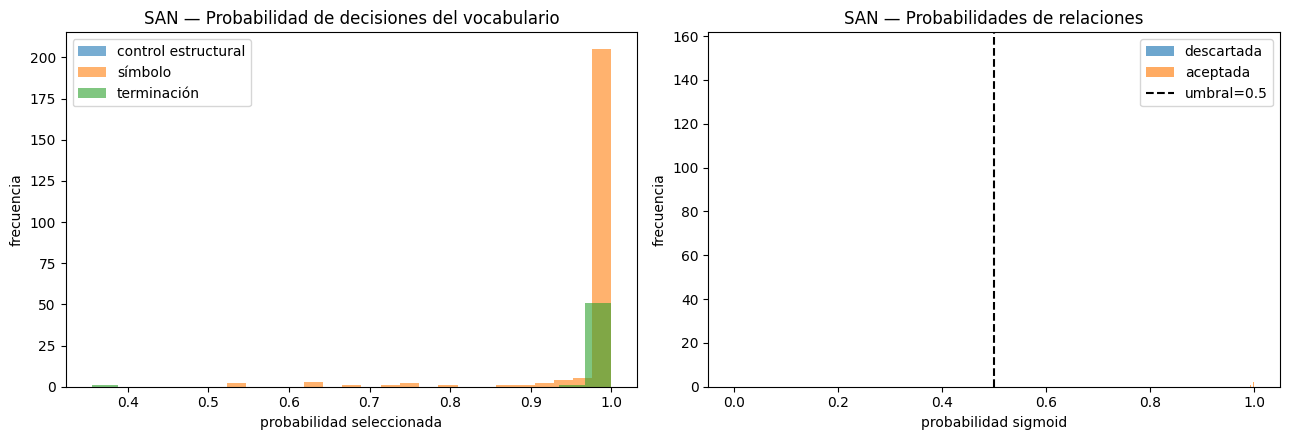

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for label, subset in tokens_df.groupby('decision_type'):
    axes[0].hist(subset['selected_probability'], bins=20, alpha=0.60, label=label)
axes[0].set(title='SAN — Probabilidad de decisiones del vocabulario', xlabel='probabilidad seleccionada', ylabel='frecuencia')
axes[0].legend()
if relations_df.empty:
    axes[1].text(0.5, 0.5, 'No hubo pasos estructurales', ha='center', va='center')
    axes[1].set_axis_off()
else:
    accepted = relations_df.loc[relations_df['accepted'] == 1, 'probability']
    rejected = relations_df.loc[relations_df['accepted'] == 0, 'probability']
    axes[1].hist(rejected, bins=20, alpha=0.65, label='descartada')
    axes[1].hist(accepted, bins=20, alpha=0.65, label='aceptada')
    axes[1].axvline(STRUCT_THRESHOLD, color='black', linestyle='--', label=f'umbral={STRUCT_THRESHOLD:g}')
    axes[1].set(title='SAN — Probabilidades de relaciones', xlabel='probabilidad sigmoid', ylabel='frecuencia')
    axes[1].legend()
fig.tight_layout()
fig.savefig(OUTPUT_PLOT, dpi=160, bbox_inches='tight')
plt.show()

## Exportación reproducible

Las trazas completas se guardan en JSON. Los CSV contienen resúmenes por muestra, por decisión del vocabulario y por relación evaluada. `decision_probability` conserva `p` para relaciones aceptadas y `1-p` para descartadas, pero aún no agrega estas cantidades en una puntuación de confianza.

In [9]:
summary = {
    'model': 'SAN (instrumentación SANv2)',
    'dataset': f'CROHME {YEAR}',
    'purpose': 'Verificación técnica de probabilidades; no calcula confianza ni evalúa reconocimiento.',
    'execution_conditions': EXECUTION_CONDITIONS,
    'random_seed': RANDOM_SEED,
    'available_samples': len(available_ids),
    'selected_samples': len(sample_ids),
    'valid_samples': len(valid_samples),
    'errors': len(errors_df),
    'validation_issues': len(issues_df),
    'predictions_equal_with_and_without_trace': bool(valid_samples['predictions_equal'].all()),
    'decoding_steps': len(tokens_df),
    'symbol_steps': int((tokens_df['decision_type'] == 'símbolo').sum()),
    'struct_control_steps': int((tokens_df['decision_type'] == 'control estructural').sum()),
    'termination_steps': int((tokens_df['decision_type'] == 'terminación').sum()),
    'relation_decisions': len(relations_df),
    'accepted_relations': int(relations_df['accepted'].sum()) if not relations_df.empty else 0,
    'rejected_relations': int((relations_df['accepted'] == 0).sum()) if not relations_df.empty else 0,
    'relation_threshold': STRUCT_THRESHOLD,
    'relation_names': RELATION_NAMES,
    'references_used_for_inference_or_probability_calculation': False,
    'padding_decision_count': padding_step_count,
    'padding_present_in_autoregressive_trace': padding_step_count > 0,
    'relation_decision_probability_rule': 'p si p > threshold; 1-p en otro caso',
    'san_checkpoint': str(san_checkpoint),
    'sanv2_checkpoint': str(sanv2_checkpoint),
    'checkpoint_sha256': san_checkpoint_sha256,
    'vocabulary_sha256': san_vocab_sha256,
    'gpu': torch.cuda.get_device_name(0),
    'python': platform.python_version(),
    'pytorch': torch.__version__,
    'cuda': torch.version.cuda,
}
valid_samples.to_csv(OUTPUT_SAMPLES, index=False, encoding='utf-8')
tokens_df.to_csv(OUTPUT_TOKENS, index=False, encoding='utf-8')
relations_df.to_csv(OUTPUT_RELATIONS, index=False, encoding='utf-8')
OUTPUT_TRACES.write_text(json.dumps(raw_traces, ensure_ascii=False, indent=2), encoding='utf-8')
OUTPUT_SUMMARY.write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
display(pd.DataFrame([summary]).T.rename(columns={0: 'valor'}))
for path in OUTPUTS:
    print(path)

,valor
model,SAN (instrumentación SANv2)
dataset,CROHME 2014
purpose,Verificación técnica de probabilidades; no cal...
execution_conditions,PENDIENTE_DE_DOCUMENTAR
random_seed,2026
available_samples,986
selected_samples,25
valid_samples,25
errors,0
validation_issues,0


/mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/Cascada/01_seleccion/resultados/verificacion_probabilidades_san_crohme_2014_muestras.csv
/mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/Cascada/01_seleccion/resultados/verificacion_probabilidades_san_crohme_2014_tokens.csv
/mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/Cascada/01_seleccion/resultados/verificacion_probabilidades_san_crohme_2014_relaciones.csv
/mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/Cascada/01_seleccion/resultados/verificacion_probabilidades_san_crohme_2014_trazas.json
/mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/Cascada/01_seleccion/resultados/resumen_verificacion_probabilidades_san_crohme_2014.json
/mnt/c/Users/novac/Documents/Unidad/Documentos/IPN/Trabajo_terminal/Programas/Cascada/01_seleccion/resultados/verificacion_probabilidades_san_crohme_2014.png


## Criterio de interpretación

La verificación respalda el uso posterior de SAN como modelo ligero únicamente si todas las comprobaciones resultan verdaderas y no existen incidencias. Esto demuestra disponibilidad y coherencia de las probabilidades, pero no demuestra todavía que una medida de confianza discrimine correctamente entre aciertos y errores. Esa evaluación debe mantenerse separada y realizarse sobre CROHME 2014 conforme a la metodología.